# Experiment 7 — Integrated urban scenario

This experiment compares three operational configurations under the same urban scenarios: **SD only**, **TD only**, and **SD + TD**. Unlike Experiment 6, the objective is not load testing. The scenario combines interacting traffic, permanent obstacles, a known geofence, a dynamically activated geofence, wind zones, first-order dynamics, and noisy sensors.

Each configuration is evaluated in ten paired replications. Within one replication, all configurations receive exactly the same initial flight plans and random seeds.

In [ ]:
import csv
import fcntl
import math
import random
from pathlib import Path
from statistics import fmean

import matplotlib.pyplot as plt
from IPython.display import display

from musas.airspace import (
    Airspace, Box3D, Cylinder3D, Geofence, Obstacle, WindZone,
)
from musas.algorithms import (
    FirstOrderDynamics,
    FlightPlanAwareTracking,
    GaussianSensor,
    MinimumSeparationConflictPrediction,
    MinimumSeparationTacticalConflictPrediction,
    RecursiveTimeShiftDeconfliction,
    VerticalManeuverDeconfliction,
    WaypointGuidance,
)
from musas.domain import FlightPlan, Waypoint
from musas.simulation import (
    Simulation, SimulationDataset, VisualizationConfig,
    calculate_metrics, plot_dataset,
    animate_dataset
)

OUTPUT_DIRECTORY = Path("outputs") / "output_exp7"
DATASET_DIRECTORY = OUTPUT_DIRECTORY / "datasets"
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
DATASET_DIRECTORY.mkdir(exist_ok=True)

## Configuration

Twelve UAVs operate inside a $500 \times 500$ area. Departures are distributed over time and three altitude layers are available. Moderate sensor noise and first-order response are applied in every configuration.

In [7]:
STRATEGIES = ("sd_only", "td_only", "sd_td")
STRATEGY_LABELS = {
    "sd_only": "SD only",
    "td_only": "TD only",
    "sd_td": "SD + TD",
}
NUMBER_OF_UAVS = 12
K = 10
BASE_SEED = 20261009
AREA_HALF_SIZE = 250.0
ALTITUDE_LAYERS = (90.0, 120.0, 150.0)
SIMULATION_END = 180.0
MINIMUM_SEPARATION_DISTANCE = 30.0
COLLISION_DISTANCE = 5.0

METRIC_KEYS = (
    "detected_strategic_conflicts",
    "detected_tactical_conflicts",
    "detected_conflicts",
    "flights", "modified_flights", "rejected_flights",
    "tactical_interventions", "collision_events",
    "geofence_violations", "loss_of_separation_events",
    "minimum_pairwise_separation", "obstacle_violations",
    "average_planned_distance", "average_actual_distance",
    "average_planned_time", "average_actual_time",
    "average_updates_per_uav", "distance_overhead_percent",
)

## Airspace and operations

Permanent obstacles and the static geofence are visible during strategic planning. The temporary geofence and both wind zones are scheduled after simulation start, so they must be handled from observed execution data by configurations that include TD.

In [8]:
def create_airspace():
    airspace = Airspace()
    for obstacle in (
        Obstacle("central-building", Box3D(-35, 25, -55, 15, 0, 115), "Central building"),
        Obstacle("east-tower", Cylinder3D(95, 55, 20, 0, 145), "East tower"),
        Obstacle("west-block", Box3D(-155, -105, -5, 55, 0, 105), "West block"),
    ):
        airspace.add_obstacle(obstacle)
    airspace.add_geofence(Geofence(
        geofence_id="static-hospital",
        name="Hospital protection zone",
        geometry=Cylinder3D(-75, 105, 35, 60, 170),
    ))
    return airspace


def dynamic_geofence():
    return Geofence(
        geofence_id="temporary-emergency",
        name="Temporary emergency zone",
        geometry=Cylinder3D(70, -75, 45, 60, 170),
    )


def wind_zones():
    return (
        (WindZone(
            "west-crosswind", Box3D(-250, -40, -180, 180, 60, 170),
            (0.0, 3.0, 0.0), name="West crosswind",
        ), 12.0, 105.0),
        (WindZone(
            "east-crosswind", Box3D(35, 250, -200, 150, 60, 170),
            (-2.0, -2.5, 0.0), name="East crosswind",
        ), 28.0, 115.0),
    )


def point_on_border(rng, border):
    coordinate = rng.uniform(-AREA_HALF_SIZE, AREA_HALF_SIZE)
    return {
        "left": (-AREA_HALF_SIZE, coordinate),
        "right": (AREA_HALF_SIZE, coordinate),
        "bottom": (coordinate, -AREA_HALF_SIZE),
        "top": (coordinate, AREA_HALF_SIZE),
    }[border]


def create_flight_plans(seed):
    rng = random.Random(seed)
    borders = ("left", "right", "bottom", "top")
    plans = {}
    for index in range(NUMBER_OF_UAVS):
        while True:
            start_border = rng.choice(borders)
            end_border = rng.choice([item for item in borders if item != start_border])
            start = point_on_border(rng, start_border)
            end = point_on_border(rng, end_border)
            if math.dist(start, end) >= 260.0:
                break
        altitude = rng.choice(ALTITUDE_LAYERS)
        departure = rng.uniform(4.0, 20.0)
        plans[f"UAV {index + 1:02d}"] = FlightPlan([
            Waypoint(*start, altitude, departure),
            Waypoint(*end, altitude, departure + 80.0),
        ])
    return plans

## Simulation function

`SD only` receives the known airspace during planning. `TD only` approves every proposal and reacts during execution. `SD + TD` combines both layers. Dynamic airspace changes are identical in all configurations.

In [9]:
def run_simulation(strategy, replication):
    seed = BASE_SEED + replication
    dataset_path = DATASET_DIRECTORY / f"{strategy}_run_{replication + 1:02d}.sqlite"
    arguments = {}

    if strategy in {"sd_only", "sd_td"}:
        strategic_predictor = MinimumSeparationConflictPrediction(
            minimum_separation_distance=MINIMUM_SEPARATION_DISTANCE,
            sampling_interval=0.75,
        )
        arguments.update(
            strategic_conflict_prediction_algorithm=strategic_predictor,
            strategic_deconfliction_algorithm=RecursiveTimeShiftDeconfliction(
                conflict_prediction_algorithm=strategic_predictor,
                time_shift_step=4.0,
                maximum_iterations=30,
            ),
        )

    if strategy in {"td_only", "sd_td"}:
        arguments.update(
            tracking_algorithm=FlightPlanAwareTracking(),
            tactical_conflict_prediction_algorithm=(
                MinimumSeparationTacticalConflictPrediction(
                    minimum_separation_distance=MINIMUM_SEPARATION_DISTANCE,
                    maximum_time_difference=0.5,
                )
            ),
            tactical_deconfliction_algorithm=VerticalManeuverDeconfliction(
                altitude_offset=60.0, airspace_clearance=12.0,
                minimum_maneuver_duration=5.0, cooldown=20.0,
            ),
        )

    simulation = Simulation(
        airspace=create_airspace(),
        report_interval=0.75, history_window=6,
        prediction_horizon=20, prediction_step=0.5,
        flight_update_interval=0.2, trajectory_record_interval=0.5,
        message_types_to_log=(),
        dataset_path=dataset_path, overwrite_dataset=True,
        keep_history_in_memory=False,
        dataset_metadata={
            "experiment": "integrated_urban_scenario",
            "strategy": strategy, "replication": replication + 1,
            "seed": seed,
        },
        **arguments,
    )
    simulation.schedule_geofence(dynamic_geofence(), 35.0, 95.0)
    for wind_zone, activation, removal in wind_zones():
        simulation.schedule_wind_zone(wind_zone, activation, removal)

    for index, (name, plan) in enumerate(create_flight_plans(seed).items()):
        simulation.add_uav(
            name=name, flight_plan=plan,
            dynamics_algorithm=FirstOrderDynamics(
                max_acceleration=5.0, velocity_time_constant=1.5,
            ),
            guidance_algorithm=WaypointGuidance(min_speed=0.0, max_speed=12.0),
            sensor_model=GaussianSensor(
                position_standard_deviation=1.5,
                velocity_standard_deviation=0.2,
                seed=seed + index,
            ),
            submission_time=index * 0.03, waypoint_acceptance_radius=2.0,
        )

    simulation.run(until=SIMULATION_END)
    simulation.close()
    with SimulationDataset(dataset_path) as dataset:
        metrics = calculate_metrics(
            dataset, MINIMUM_SEPARATION_DISTANCE, COLLISION_DISTANCE,
        )
    metrics["detected_conflicts"] = (
        metrics["detected_strategic_conflicts"]
        + metrics["detected_tactical_conflicts"]
    )
    metrics["average_updates_per_uav"] = fmean(
        values["updates"] for values in metrics["per_uav"].values()
    )
    planned = metrics["average_planned_distance"]
    actual = metrics["average_actual_distance"]
    metrics["distance_overhead_percent"] = (
        None if planned in (None, 0) or actual is None
        else 100.0 * (actual - planned) / planned
    )
    return {
        "strategy": strategy, "replication": replication + 1,
        "seed": seed,
        **{key: metrics[key] for key in METRIC_KEYS},
    }

In [10]:
def execute_experiment():
    lock_path = OUTPUT_DIRECTORY / "experiment.lock"
    with lock_path.open("w") as lock_file:
        try:
            fcntl.flock(lock_file, fcntl.LOCK_EX | fcntl.LOCK_NB)
        except BlockingIOError as error:
            raise RuntimeError("Experiment 7 is already running") from error
        results = []
        for strategy in STRATEGIES:
            for replication in range(K):
                print(
                    f"{STRATEGY_LABELS[strategy]:7s} | "
                    f"replication={replication + 1:02d}/{K}", end="\r",
                )
                results.append(run_simulation(strategy, replication))
            print(f"{STRATEGY_LABELS[strategy]:7s} | completed {K} replications")
        return results


results = execute_experiment()
raw_path = OUTPUT_DIRECTORY / "replication_metrics.csv"
with raw_path.open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=results[0].keys())
    writer.writeheader()
    writer.writerows(results)
print("Saved:", raw_path)

SD only | completed 10 replications
TD only | completed 10 replications
SD + TD | completed 10 replications
Saved: outputs/output_exp7/replication_metrics.csv


## Mean results and comparison

Counts are averaged per simulation. Distance and time values are first averaged over flights that actually started and then over the ten replications.

In [11]:
def mean_defined(values):
    values = [value for value in values if value is not None]
    return fmean(values) if values else None


mean_metrics = []
for strategy in STRATEGIES:
    group = [row for row in results if row["strategy"] == strategy]
    mean_metrics.append({
        "strategy": strategy,
        **{key: mean_defined([row[key] for row in group]) for key in METRIC_KEYS},
    })

summary_path = OUTPUT_DIRECTORY / "mean_metrics.csv"
with summary_path.open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=mean_metrics[0].keys())
    writer.writeheader()
    writer.writerows(mean_metrics)

print(f"{'Strategy':<9} {'conflicts':>10} {'modified':>9} {'rejected':>9} {'LOS':>7} {'coll.':>7} {'geof.':>7} {'obst.':>7} {'min.sep.':>9} {'extra %':>9}")
for row in mean_metrics:
    print(
        f"{STRATEGY_LABELS[row['strategy']]:<9} "
        f"{row['detected_conflicts']:10.2f} {row['modified_flights']:9.2f} "
        f"{row['rejected_flights']:9.2f} {row['loss_of_separation_events']:7.2f} "
        f"{row['collision_events']:7.2f} {row['geofence_violations']:7.2f} "
        f"{row['obstacle_violations']:7.2f} {row['minimum_pairwise_separation']:9.2f} "
        f"{row['distance_overhead_percent']:9.2f}"
    )
print("Saved:", summary_path)

Strategy   conflicts  modified  rejected     LOS   coll.   geof.   obst.  min.sep.   extra %
SD only         7.30      5.00      0.00    1.50    0.00    3.90    0.50     21.77      5.93
TD only       241.80     11.00      0.00    3.70    0.20    1.90    1.00     12.44     37.35
SD + TD       239.90     11.00      0.00    3.40    0.20    1.90    0.50     12.54     34.36
Saved: outputs/output_exp7/mean_metrics.csv


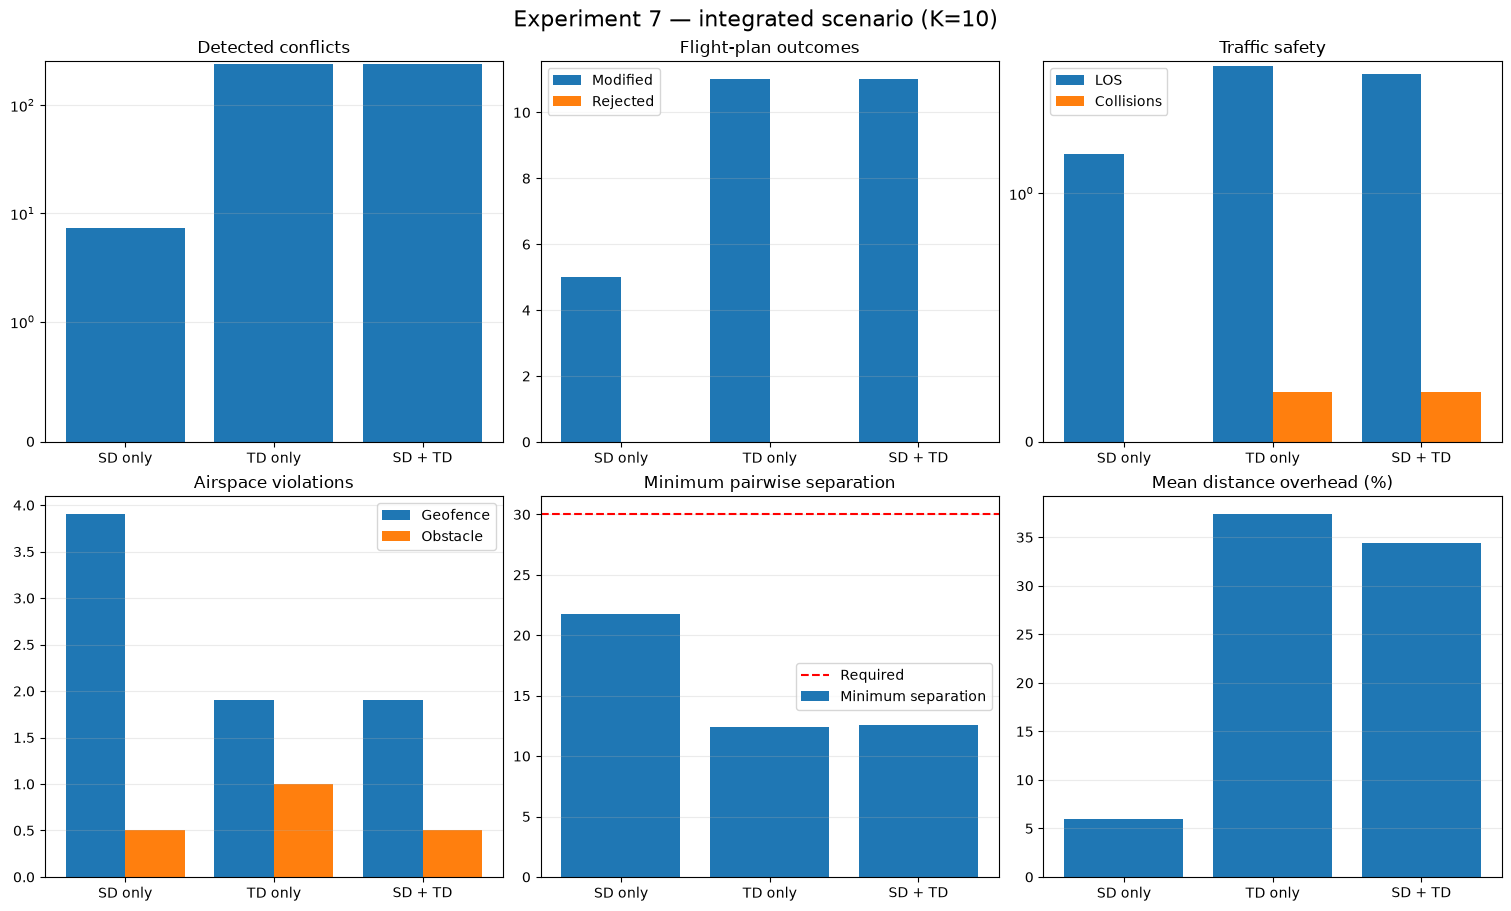

Saved: outputs/output_exp7/mean_metrics.png


In [17]:
labels = [STRATEGY_LABELS[row["strategy"]] for row in mean_metrics]
x = range(len(labels))
figure, axes = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)

def bars(axis, keys, names, title, log=False):
    width = 0.8 / len(keys)
    for index, (key, name) in enumerate(zip(keys, names)):
        positions = [value - 0.4 + width / 2 + index * width for value in x]
        axis.bar(positions, [row[key] for row in mean_metrics], width, label=name)
    axis.set_title(title)
    axis.set_xticks(list(x), labels)
    axis.grid(axis="y", alpha=0.25)
    if log:
        axis.set_yscale("symlog", linthresh=1.0)
    if len(keys) > 1:
        axis.legend()

bars(axes[0, 0], ("detected_conflicts",), ("Conflicts",), "Detected conflicts", True)
bars(axes[0, 1], ("modified_flights", "rejected_flights"), ("Modified", "Rejected"), "Flight-plan outcomes")
bars(axes[0, 2], ("loss_of_separation_events", "collision_events"), ("LOS", "Collisions"), "Traffic safety", True)
bars(axes[1, 0], ("geofence_violations", "obstacle_violations"), ("Geofence", "Obstacle"), "Airspace violations")
bars(axes[1, 1], ("minimum_pairwise_separation",), ("Minimum separation",), "Minimum pairwise separation")
axes[1, 1].axhline(MINIMUM_SEPARATION_DISTANCE, color="red", linestyle="--", label="Required")
axes[1, 1].legend()
bars(axes[1, 2], ("distance_overhead_percent",), ("Extra distance",), "Mean distance overhead (%)")
figure.suptitle(f"Experiment 7 — integrated scenario (K={K})", fontsize=16)
figure_path = OUTPUT_DIRECTORY / "mean_metrics.png"
figure.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", figure_path)

## One visual example per configuration

These top views use replication 1 at the time when the dynamic geofence and wind zones are active. Legends are disabled because twelve UAVs would make them excessively large.

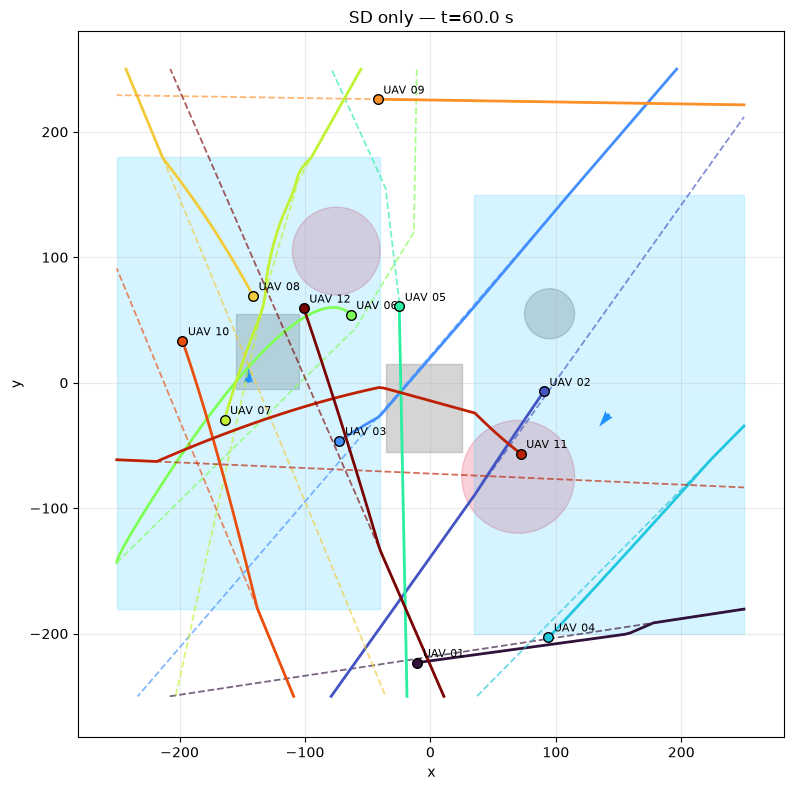

Saved: outputs/output_exp7/sd_only_t60.png


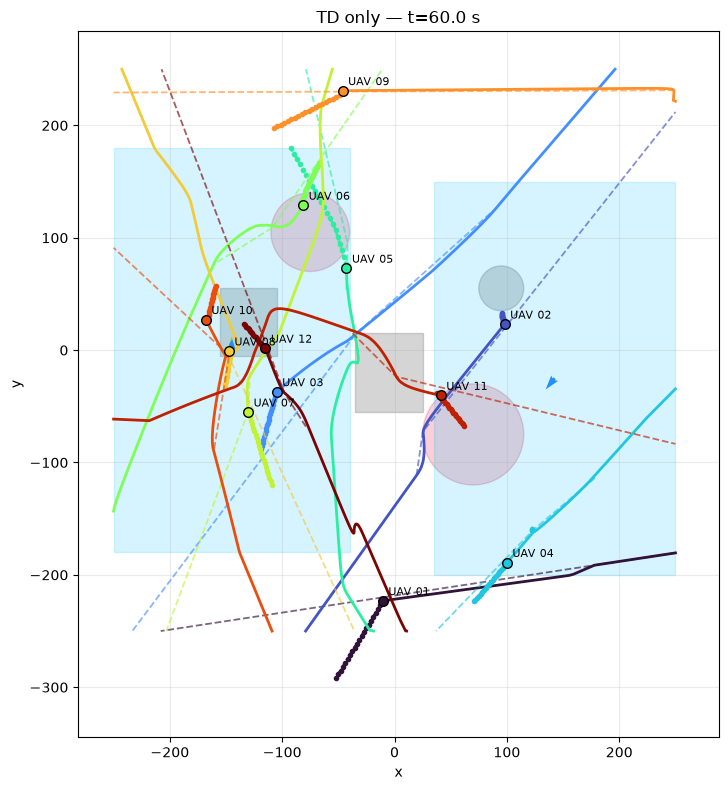

Saved: outputs/output_exp7/td_only_t60.png


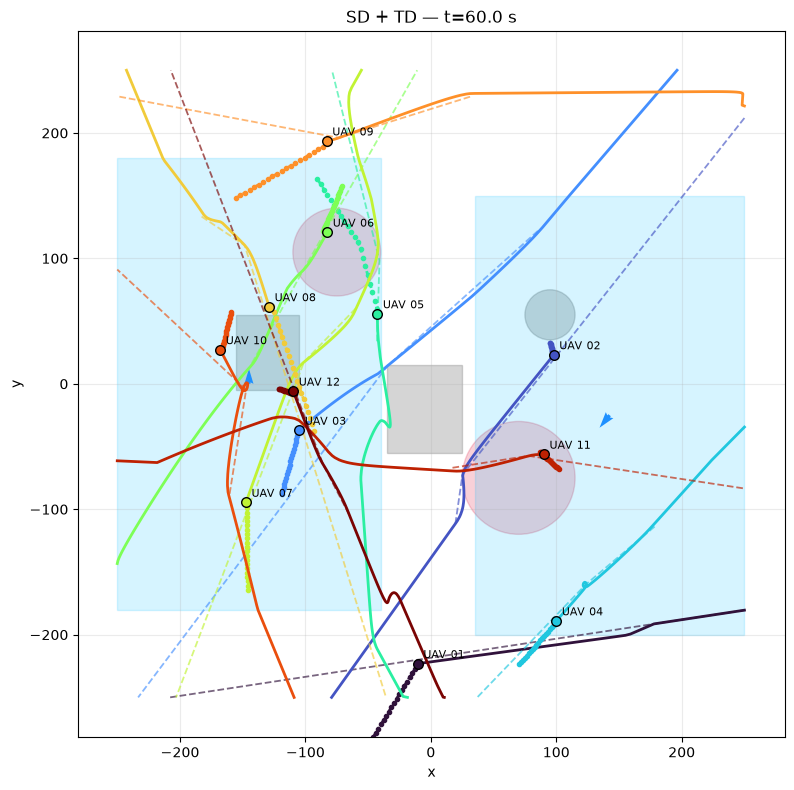

Saved: outputs/output_exp7/sd_td_t60.png


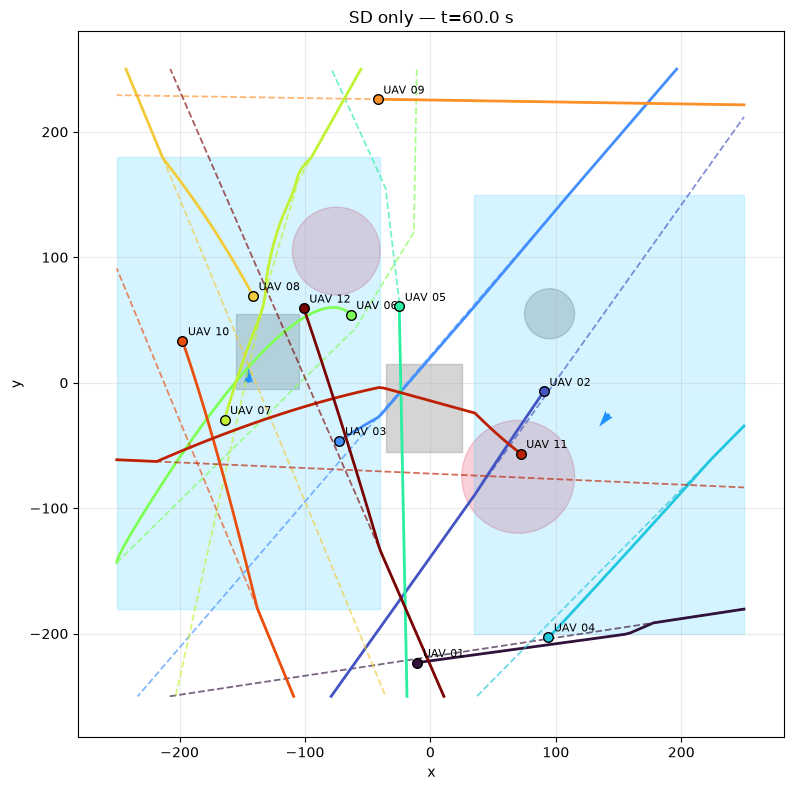

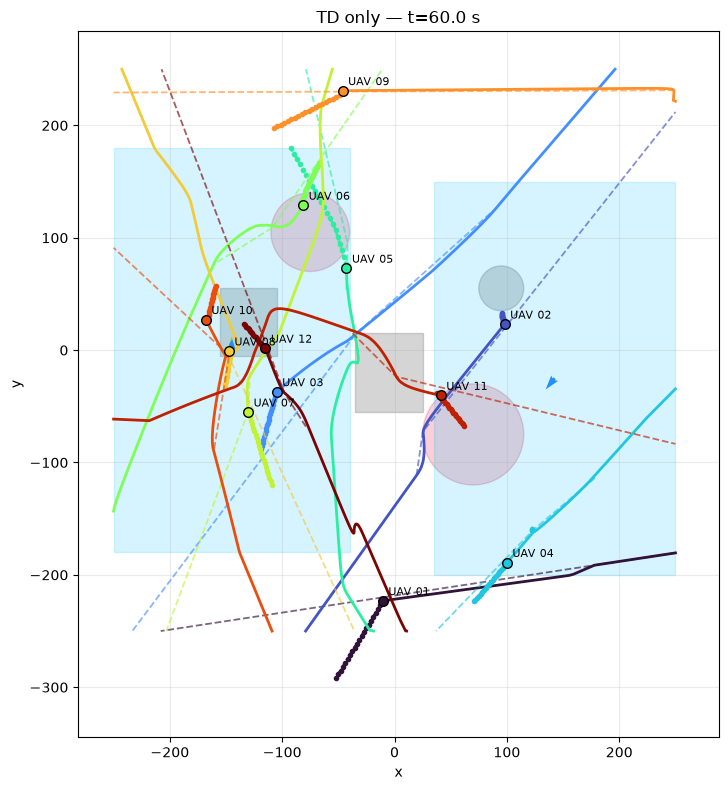

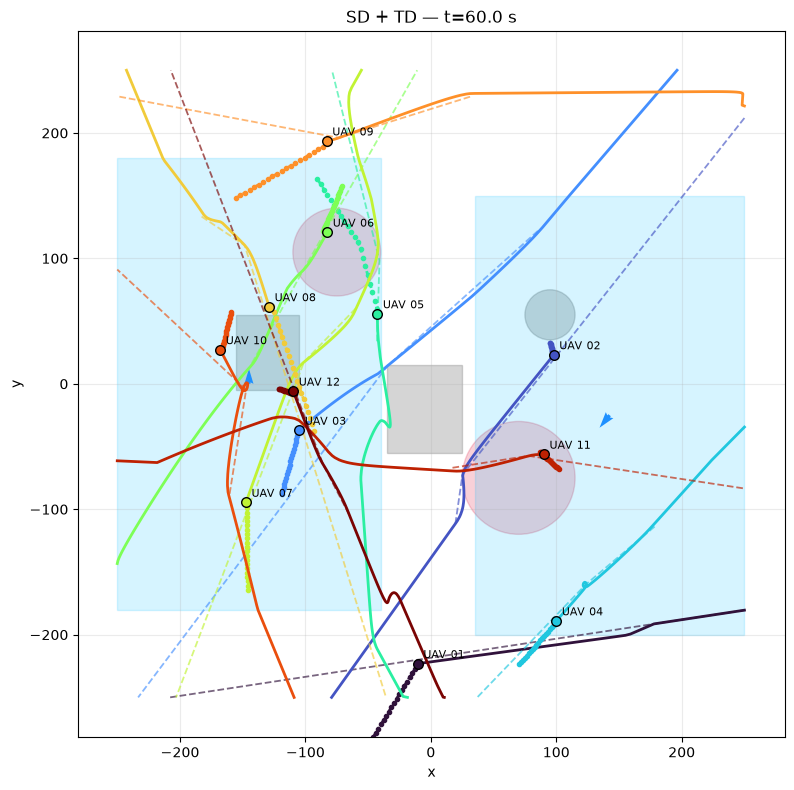

In [ ]:
for strategy in STRATEGIES:
    dataset_path = DATASET_DIRECTORY / f"{strategy}_run_01.sqlite"
    image_path = OUTPUT_DIRECTORY / f"{strategy}_t60.png"
    figure = plot_dataset(
        dataset_path=dataset_path,
        timestamp=60.0,
        output_path=image_path,
        config=VisualizationConfig(
            uav_names=None, view="xy",
            show_real_trajectories=True, show_current_positions=True,
            show_flight_plans=True,
            show_tracks=strategy in {"td_only", "sd_td"},
            show_sensor_reports=False, show_geofences=True,
            show_wind_zones=True, show_obstacles=True,
            show_legend=False, figure_size=(10.0, 8.0),
            title=STRATEGY_LABELS[strategy],
        ),
    )
    display(figure)
    print("Saved:", image_path)